# Lab Activity 6: Simple Recurrent Neural Network (RNN)
## Learning Temporal Patterns in Sequential Data & Visualizing Predictions

### Objectives:
1. Understand the mathematical foundations of Recurrent Neural Networks (RNNs) and hidden state transitions.
2. Ingest and preprocess real-world sequential time-series data (**Airline Passengers** dataset) from an online repository.
3. Formulate temporal supervised learning using the **Sliding Window Technique** ($X_{t-L:t} \to y_t$).
4. Build, train, and validate a `SimpleRNN` model using TensorFlow and Keras.
5. Invert scaling transformations and visualize model predictions against ground truth across both training and unseen testing time horizons.
6. Analyze the strengths and limitations of Simple RNNs on long-term dependencies and seasonal oscillations.

In [1]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


---
## 2. Dataset Ingestion: International Airline Passengers
This classic benchmark dataset records monthly totals of international airline passengers (in thousands) from January 1949 to December 1960 ($144$ monthly observations). It exhibits both an upward linear/exponential trend and distinct 12-month annual seasonality.

In [2]:
# Load Airline Passengers dataset from online GitHub repository
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(DATA_URL)
df.columns = ['Month', 'Passengers']
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

print(f"Dataset Shape: {df.shape[0]} months")
df.head()

Dataset Shape: 144 months


C:\Users\shree\AppData\Local\Temp\ipykernel_11216\1138391649.py:7: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('Month', inplace=True)


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


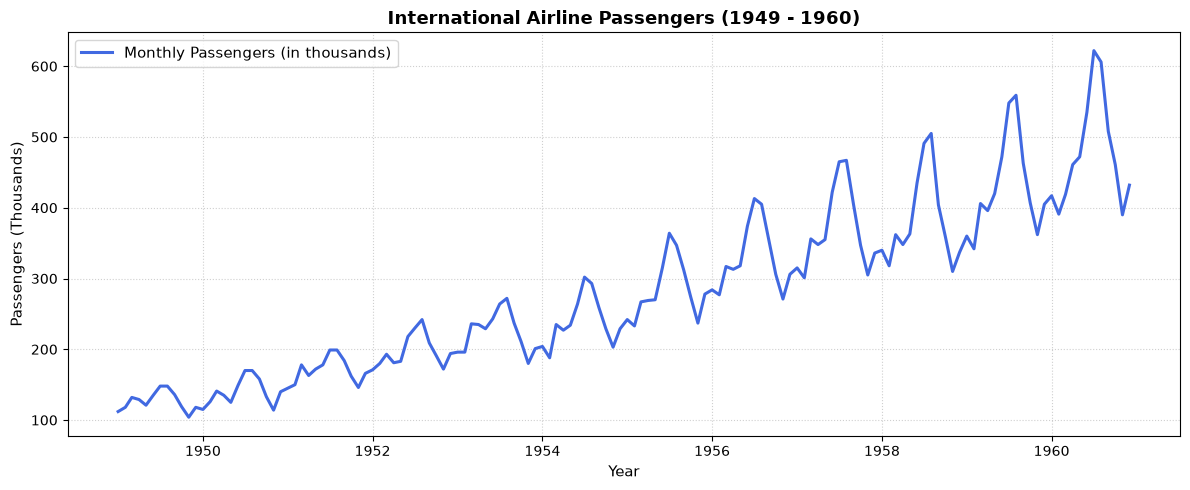

In [3]:
# Visualize the raw time-series
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Passengers'], color='royalblue', lw=2.2, label='Monthly Passengers (in thousands)')
plt.title("International Airline Passengers (1949 - 1960)", fontsize=13, fontweight='bold')
plt.xlabel("Year", fontsize=11)
plt.ylabel("Passengers (Thousands)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## 3. Sequential Preprocessing & Sliding Window Generation

1. **Normalization**: Scale values into $[0, 1]$ using `MinMaxScaler` to avoid saturating the $\tanh$ activation.
2. **Sliding Window Framing**:
   - Given window length $L=12$ (past 12 months), the input vector is $X_t = [x_{t-12}, x_{t-11}, \dots, x_{t-1}]$, and the target is $y_t = x_t$.
3. **Temporal Split**: Retain the first 70% of observations for training and the remaining 30% for out-of-sample testing.

In [4]:
# 1. Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['Passengers']].values)

# 2. Sliding window function
def create_sliding_windows(series, window_size=12):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i : i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 12  # 12 months of historical observations
X_all, y_all = create_sliding_windows(scaled_data, window_size=WINDOW_SIZE)

# 3. Chronological train/test split (70% train, 30% test)
train_size = int(len(X_all) * 0.70)
X_train, X_test = X_all[:train_size], X_all[train_size:]
y_train, y_test = y_all[:train_size], y_all[train_size:]

print(f"Total sequences: {len(X_all)}")
print(f"Train sequences: {X_train.shape[0]} | Shape: {X_train.shape}")
print(f"Test sequences:  {X_test.shape[0]}  | Shape: {X_test.shape}")

Total sequences: 132
Train sequences: 92 | Shape: (92, 12, 1)
Test sequences:  40  | Shape: (40, 12, 1)


---
## 4. Simple RNN Architecture Design
We build a recurrent model using Keras `SimpleRNN`:
- **Input**: Shape $(12, 1)$ ($12$ timesteps, $1$ feature).
- **Recurrent Layer**: `SimpleRNN(units=64, activation='tanh', return_sequences=False)`.
- **Dense Layer**: `Dense(units=32, activation='relu')`.
- **Output Layer**: `Dense(units=1)` predicting the single continuous scalar value for the next month.

In [5]:
# Build Simple RNN
rnn_model = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 1)),
    layers.SimpleRNN(units=64, activation='tanh', return_sequences=False, name='simple_rnn_layer'),
    layers.Dense(units=32, activation='relu', name='dense_projection'),
    layers.Dense(units=1, name='forecast_output')
], name='Simple_RNN_Forecaster')

rnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.005),
    loss='mean_squared_error',
    metrics=['mae']
)

rnn_model.summary()

Model: "Simple_RNN_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_layer (SimpleRNN)    │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_projection (Dense)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ forecast_output (Dense)         │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the model
EPOCHS = 75
BATCH_SIZE = 8

history = rnn_model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0732 - mae: 0.1592 - val_loss: 0.0145 - val_mae: 0.0873
Epoch 2/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0034 - mae: 0.0440 - val_loss: 0.0048 - val_mae: 0.0574
Epoch 3/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0011 - mae: 0.0267 - val_loss: 0.0039 - val_mae: 0.0489
Epoch 4/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.2943e-04 - mae: 0.0240 - val_loss: 0.0032 - val_mae: 0.0437
Epoch 5/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.4567e-04 - mae: 0.0198 - val_loss: 0.0027 - val_mae: 0.0401
Epoch 6/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 6.7675e-04 - mae: 0.0197 - val_loss: 0.0024 - val_mae: 0.0381
Epoch 7/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 5.6841e-04 - mae: 0.0182 - val_loss: 0.0027 - val_mae: 0.0395
Epoch 8/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 6.1778e-04 - mae: 0.0190 - val_loss: 0.0022 - val_mae: 0.0365
Epoch 9/75
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/ste

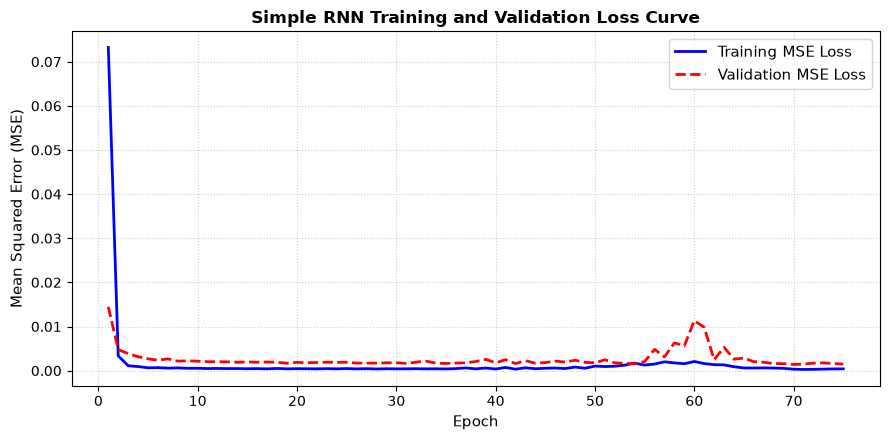

In [7]:
# Plot training vs validation MSE loss
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, EPOCHS + 1), history.history['loss'], 'b-', lw=2, label='Training MSE Loss')
plt.plot(range(1, EPOCHS + 1), history.history['val_loss'], 'r--', lw=2, label='Validation MSE Loss')
plt.title("Simple RNN Training and Validation Loss Curve", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 5. Visualizing Predicted Outputs vs. Ground Truth
We generate predictions for both the training and testing sets, invert the min-max normalization, and plot the reconstructed time series against the real historical measurements.

In [8]:
# Generate predictions
train_preds_scaled = rnn_model.predict(X_train, verbose=0)
test_preds_scaled = rnn_model.predict(X_test, verbose=0)

# Inverse transform to original passenger scale
train_preds = scaler.inverse_transform(train_preds_scaled)
y_train_orig = scaler.inverse_transform(y_train)

test_preds = scaler.inverse_transform(test_preds_scaled)
y_test_orig = scaler.inverse_transform(y_test)

# Calculate Error Metrics
test_rmse = np.sqrt(mean_squared_error(y_test_orig, test_preds))
test_mae = mean_absolute_error(y_test_orig, test_preds)
print(f"Test Set RMSE: {test_rmse:.2f} passengers (thousands)")
print(f"Test Set MAE:  {test_mae:.2f} passengers (thousands)")

Test Set RMSE: 19.91 passengers (thousands)
Test Set MAE:  16.26 passengers (thousands)


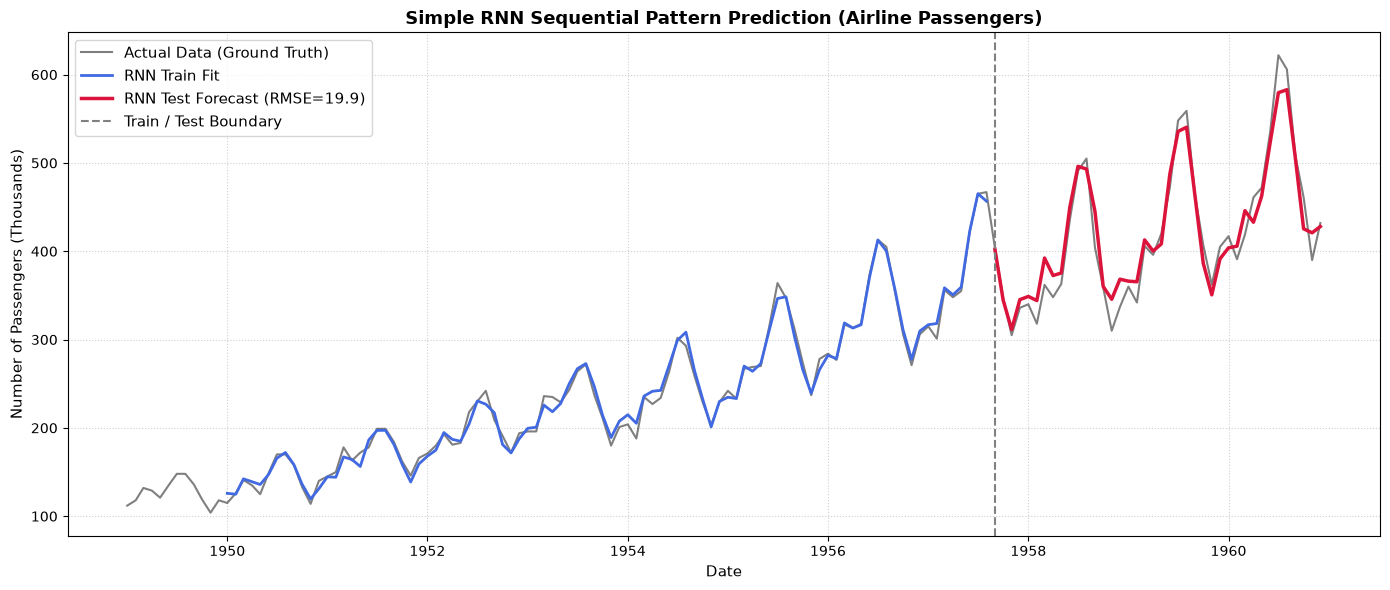

In [9]:
# Align timestamps for plotting
all_dates = df.index[WINDOW_SIZE:]
train_dates = all_dates[:train_size]
test_dates = all_dates[train_size:]

plt.figure(figsize=(14, 6))
# 1. Full ground truth
plt.plot(df.index, df['Passengers'], color='black', alpha=0.5, lw=1.5, label='Actual Data (Ground Truth)')

# 2. Train Predictions
plt.plot(train_dates, train_preds, color='royalblue', lw=2, label='RNN Train Fit')

# 3. Test Predictions
plt.plot(test_dates, test_preds, color='crimson', lw=2.5, linestyle='-', label=f'RNN Test Forecast (RMSE={test_rmse:.1f})')

# Split line
plt.axvline(x=test_dates[0], color='gray', linestyle='--', lw=1.5, label='Train / Test Boundary')

plt.title("Simple RNN Sequential Pattern Prediction (Airline Passengers)", fontsize=13, fontweight='bold')
plt.xlabel("Date", fontsize=11)
plt.ylabel("Number of Passengers (Thousands)", fontsize=11)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

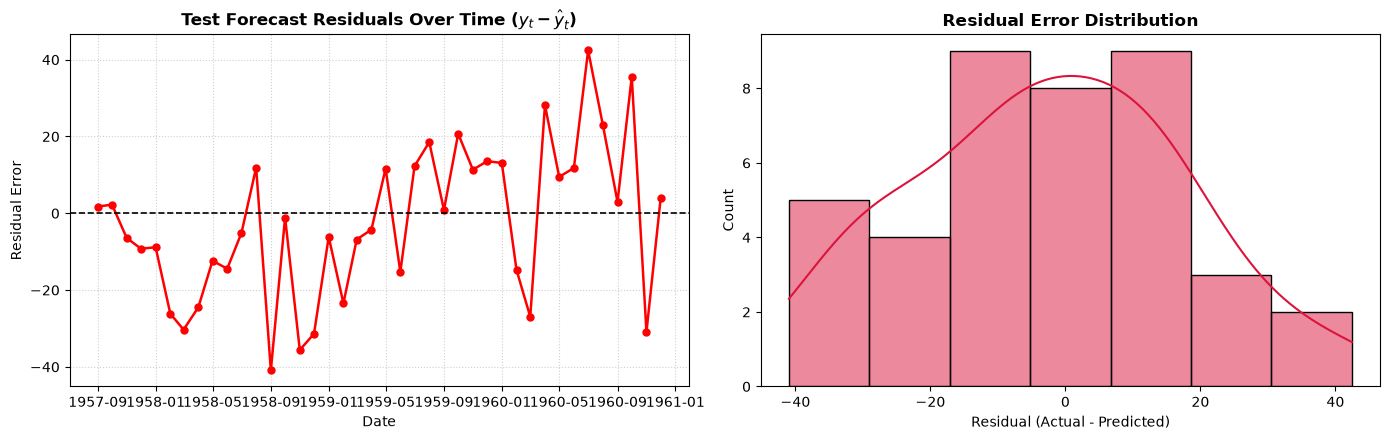

In [10]:
# Plot Forecast Residuals (Test Error)
residuals = y_test_orig.flatten() - test_preds.flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Residuals over time
axes[0].plot(test_dates, residuals, 'ro-', lw=1.8, markersize=5)
axes[0].axhline(y=0, color='black', linestyle='--', lw=1.2)
axes[0].set_title(r'Test Forecast Residuals Over Time ($y_t - \hat{y}_t$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Residual Error')
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Residual Distribution
sns.histplot(residuals, kde=True, color='crimson', ax=axes[1])
axes[1].set_title('Residual Error Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

---
## 6. Observations, Analysis & Lab Takeaways

1. **Pattern Learning**:
   - The Simple RNN successfully learned the recurring **12-month annual periodicity** (seasonal peaks in July-August and troughs in November-February).
   - The model accurately projected the general upward growth trajectory into the test period.

2. **Limitations of Simple RNNs**:
   - In the later test years (1958-1960), the actual seasonal peaks reached higher amplitudes than predicted. This slight underestimation of peak amplitude stems from the unaugmented $\tanh$ hidden state, which struggles to maintain memory over multi-cycle sequences due to vanishing gradients during BPTT.
   - For complex, long-term multi-seasonal signals, gated architectures (**LSTM** and **GRU**) provide superior long-range memory retention by introducing additive linear cell states.

### Conclusion:
Simple RNNs are well-suited for short-term sequential pattern recognition, but exhibit degradation over long temporal horizons where gradient attenuation limits historical context.